# Depurar un modelo paso a paso: la receta de Full Stack Deep Learning

Cuando un modelo no aprende, el código casi nunca avisa. No hay una excepción ni una línea roja: la pérdida simplemente baja menos de lo esperado, o se queda quieta, o la exactitud de prueba es mediocre y no se sabe por qué. Según el curso **Full Stack Deep Learning** (FSDL), es común que quienes entrenan redes digan que pasan entre el 80% y el 90% de su tiempo depurando y ajustando modelos, y solo el resto deduciendo ecuaciones e implementando ([*Overview*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging/overview)).

La lección [*Training and Debugging*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging) de FSDL (Josh Tobin, 2019; las notas de su versión de 2021 están en [*Lecture 7: Troubleshooting Deep Neural Networks*](https://fullstackdeeplearning.com/spring2021/lecture-7/)) propone una receta para ese 80%: empezar con lo más simple que pueda funcionar, comprobar que el código hace lo que creemos, medir dónde está el error, y recién entonces mejorar y ajustar. Este notebook la sigue paso a paso con MNIST. Cada afirmación que viene de una fuente lleva un link a la sección donde está, y la sección **Fuentes**, al final, reúne las citas textuales:

- Siembra bugs a propósito y muestra la **firma** que deja cada uno en la curva de pérdida cuando se intenta sobreajustar un solo lote.
- Descompone el error en **sesgo** y **varianza**, y deja que esa descomposición decida qué arreglar primero.
- Compara la búsqueda de hiperparámetros en **grilla** con la búsqueda **aleatoria** y la búsqueda **de lo grueso a lo fino**.

El notebook tarda unos tres minutos en una CPU.

**Contenido**

1. Preparación
2. La receta
3. Empezar simple
4. Que corra
5. Sobreajustar un solo lote
6. El zoológico de bugs
7. Comparar con un resultado conocido
8. Evaluar: sesgo y varianza
9. Mejorar: primero el sesgo, después la varianza
10. Ajustar hiperparámetros
11. La prueba, una sola vez
12. Resumen y ejercicios

## 1. Preparación

Precargamos MNIST en memoria y normalizado, como en `04-clasificacion-de-imagenes/02_experimentos_con_mnist`. De las 60.000 imágenes de entrenamiento apartamos 10.000 para validación. La prueba queda guardada hasta la sección 11.

In [1]:
import math
import time

import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets
import matplotlib.pyplot as plt

print("Versión de PyTorch:", torch.__version__)

MEDIA, DESVIACION = 0.1307, 0.3081
FONDO = (0 - MEDIA) / DESVIACION          # el valor de un píxel negro, ya normalizado


def precargar(entrenamiento):
    datos = datasets.MNIST(root="../data", train=entrenamiento, download=True)
    imagenes = ((datos.data.float() / 255 - MEDIA) / DESVIACION).unsqueeze(1)
    return imagenes, datos.targets


X_todo, y_todo = precargar(True)
X_prueba, y_prueba = precargar(False)

orden = torch.randperm(len(X_todo), generator=torch.Generator().manual_seed(0))
X_entrenamiento, y_entrenamiento = X_todo[orden[:50_000]], y_todo[orden[:50_000]]
X_validacion, y_validacion = X_todo[orden[50_000:]], y_todo[orden[50_000:]]
print("entrenamiento:", len(X_entrenamiento), "  validación:", len(X_validacion), "  prueba:", len(X_prueba))

Versión de PyTorch: 2.11.0+cpu


entrenamiento: 50000   validación: 10000   prueba: 10000


## 2. La receta

La lección organiza la depuración en cinco pasos, que son sus secciones ([2021, secciones 3 a 7](https://fullstackdeeplearning.com/spring2021/lecture-7/#2-strategy-to-debug-neural-networks)):

1. **Empezar simple**: la arquitectura más sencilla que tenga sentido, valores por defecto razonables, entradas normalizadas y un problema más chico.
2. **Implementar y depurar**: lograr que el modelo corra, que pueda **sobreajustar un solo lote** y que reproduzca un **resultado conocido**.
3. **Evaluar**: descomponer el error para saber si el problema es de sesgo, de varianza o de un cambio en la distribución de los datos.
4. **Mejorar** el modelo o los datos, atacando primero la parte más grande del error.
5. **Ajustar los hiperparámetros**.

La lección supone que antes de empezar hay una meta: un rendimiento fijado a partir del desempeño humano, de resultados publicados o de modelos anteriores. Después de ajustar se vuelve a evaluar, y el ciclo sigue hasta alcanzarla. La razón para ir en este orden, según la lección, es que "most bugs in deep learning are actually invisible" y que es difícil distinguir un error de otro, así que conviene "start simple and gradually ramp up complexity" ([2021, secciones 1 y 2](https://fullstackdeeplearning.com/spring2021/lecture-7/#1-why-is-deep-learning-troubleshooting-hard)). Un modelo con un error de signo o con las etiquetas cambiadas puede entrenar sin ningún mensaje de error y dar un resultado solo un poco peor que el correcto. Cada paso de la receta está pensado para que los bugs aparezcan lo antes posible, cuando todavía es barato encontrarlos.

## 3. Empezar simple

Los valores por defecto que recomienda FSDL ([*Start Simple*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging/start-simple)), y lo que usamos aquí:

| Decisión | Recomendación de FSDL | Aquí |
|---|---|---|
| Arquitectura | LeNet o ResNet para imágenes ("LeNet/ResNet for images"; la versión de 2021 dice empezar con una "LeNet-like" y pasar a algo como ResNet más adelante), LSTM para secuencias, una red densa con una capa oculta para lo demás | una red densa con una capa oculta (las convolucionales vienen en un módulo posterior) |
| Optimizador | Adam con tasa $3 \times 10^{-4}$ | igual |
| Activación | ReLU para redes densas y convolucionales (TanH para LSTM) | igual |
| Inicialización | He para ReLU (Glorot para TanH) | He en las capas seguidas de ReLU; la de salida, la de PyTorch |
| Regularización | ninguna | ninguna |
| Entradas | restar la media y dividir (FSDL escribe "by the variance"; lo usual, y lo que hacemos, es dividir por la desviación estándar) | media 0.1307 y desviación 0.3081 (`00-datos/01_transforms_dataset_y_dataloader`) |
| Datos | un conjunto chico, de unos 10.000 ejemplos | las primeras 10.000 imágenes de entrenamiento |

La inicialización por defecto de `nn.Linear` no es la de He: usa una uniforme con varianza $1/(3 n_\text{entrada})$, seis veces más chica que la de He, $2/n_\text{entrada}$ (`04-matematica-de-pytorch/02_capas_y_activaciones` del módulo 1). La cambiamos con `nn.init.kaiming_normal_`, que es el nombre de la inicialización de He en PyTorch (Kaiming es el nombre de pila de He), en las capas que van seguidas de una ReLU, que son para las que se dedujo. La capa de salida no tiene ReLU y conserva la inicialización de PyTorch; la sección 4 muestra por qué importa.

`entrenar` recorre los datos en lotes de 64 con Adam, y puede aplicar un aumento de datos que usaremos en la sección 9.

In [2]:
def red(*ocultas):
    # Una red densa con las capas ocultas indicadas; sin argumentos, un clasificador lineal
    torch.manual_seed(0)
    capas, entrada = [nn.Flatten()], 784
    for ancho in ocultas:
        lineal = nn.Linear(entrada, ancho)
        nn.init.kaiming_normal_(lineal.weight, nonlinearity="relu")
        nn.init.zeros_(lineal.bias)
        capas += [lineal, nn.ReLU()]
        entrada = ancho
    capas.append(nn.Linear(entrada, 10))
    return nn.Sequential(*capas)


def desplazar(xb, generador, maximo=2):
    # Mueve cada imagen hasta `maximo` píxeles en cada eje; lo que entra por el borde es fondo
    n = len(xb)
    lienzo = F.pad(xb, (maximo,) * 4, value=FONDO)
    dy = torch.randint(0, 2 * maximo + 1, (n,), generator=generador)
    dx = torch.randint(0, 2 * maximo + 1, (n,), generator=generador)
    filas = (dy[:, None] + torch.arange(28))[:, :, None]
    columnas = (dx[:, None] + torch.arange(28))[:, None, :]
    return lienzo[torch.arange(n)[:, None, None], 0, filas, columnas].unsqueeze(1)


def entrenar(modelo, X, y, epocas, lr=3e-4, aumentar=False, tamano_lote=64, semilla=1):
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    criterio = nn.CrossEntropyLoss()
    generador = torch.Generator().manual_seed(semilla)
    modelo.train()
    for _ in range(epocas):
        orden = torch.randperm(len(X), generator=generador)
        for i in range(0, len(X), tamano_lote):
            indices = orden[i:i + tamano_lote]
            xb = desplazar(X[indices], generador) if aumentar else X[indices]
            perdida = criterio(modelo(xb), y[indices])
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()
    return modelo


def error(modelo, X, y):
    modelo.eval()
    with torch.no_grad():
        return (modelo(X).argmax(dim=1) != y).float().mean().item()


X_chico, y_chico = X_entrenamiento[:10_000], y_entrenamiento[:10_000]
print("ejemplos por dígito en el conjunto chico:", torch.bincount(y_chico).tolist())

ejemplos por dígito en el conjunto chico: [953, 1167, 1018, 1066, 967, 921, 920, 1045, 931, 1012]


## 4. Que corra

FSDL enumera los cinco bugs más comunes en deep learning ([*Debug*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging/debug)):

1. tensores con la forma equivocada;
2. entradas mal preprocesadas;
3. una entrada equivocada a la función de pérdida;
4. olvidar poner la red en el modo correcto (`train()` o `eval()`);
5. inestabilidad numérica: valores `inf` o `NaN`.

El primero suele dar una excepción y se ve de inmediato (`01-modelos/01_nn_module`, sección 6). Los otros cuatro no: el código corre y entrega números. Antes de entrenar, entonces, conviene mirar los números de una pasada hacia adelante. Hay un valor que sabemos de antemano: con pesos aleatorios, la red no tiene preferencia por ninguna clase, así que debería asignar alrededor de 1/10 a cada una, y la entropía cruzada debería estar cerca de $-\ln(1/10) = \ln 10 \approx 2.30$.

In [3]:
modelo = red(256)
xb, yb = X_chico[:64], y_chico[:64]
logits = modelo(xb)
perdida = nn.CrossEntropyLoss()(logits, yb)

print("forma de la entrada:", tuple(xb.shape), " forma de la salida:", tuple(logits.shape))
print("rango de la entrada:", f"{xb.min():.2f} a {xb.max():.2f}", " media:", f"{xb.mean():.3f}")
print(f"pérdida inicial: {perdida.item():.3f}   (ln 10 = {math.log(10):.3f})")
print(f"probabilidad media de la clase correcta: {logits.softmax(dim=1)[torch.arange(64), yb].mean():.3f}")
print("¿algún NaN o inf?", not torch.isfinite(logits).all().item())

forma de la entrada: (64, 1, 28, 28)  forma de la salida: (64, 10)
rango de la entrada: -0.42 a 2.82  media: 0.002
pérdida inicial: 2.133   (ln 10 = 2.303)
probabilidad media de la clase correcta: 0.137
¿algún NaN o inf? False


Todo en orden: las formas son las esperadas, la entrada está centrada (media 0.002; va de -0.42, el fondo negro, a 2.82, un píxel blanco), no hay `NaN`, y la pérdida inicial, 2.13, está cerca de $\ln 10$. Que quede un poco por debajo es casualidad del lote: en estas 64 imágenes la red asigna en promedio 0.137 a la clase correcta, algo más que 1/10.

¿Por qué la capa de salida conserva la inicialización de PyTorch? Veamos qué pasa si también usa la de He:

In [4]:
con_he_en_la_salida = red(256)
nn.init.kaiming_normal_(con_he_en_la_salida[-1].weight, nonlinearity="relu")
logits = con_he_en_la_salida(xb)
print(f"desviación de los logits: {logits.std():.2f} con He en la salida, "
      f"{modelo(xb).std():.2f} con la inicialización de PyTorch")
print(f"pérdida inicial con He en la salida: {nn.CrossEntropyLoss()(logits, yb).item():.3f}")

desviación de los logits: 1.63 con He en la salida, 0.52 con la inicialización de PyTorch
pérdida inicial con He en la salida: 3.353


Con He en la salida, los logits iniciales tienen una desviación de 1.63, tres veces más que con la inicialización de PyTorch, y la pérdida inicial sube a 3.35: la red parte opinando con fuerza, al azar, y se equivoca con confianza. La inicialización de He duplica la varianza de los pesos para compensar que la ReLU siguiente anula la mitad de las entradas. En la capa de salida no hay ReLU, y esa compensación sobra. No impide entrenar, pero los primeros pasos se gastan en deshacer una confianza que no se ganó. Es el tipo de cosa que mirar la pérdida inicial detecta antes de entrenar.

## 5. Sobreajustar un solo lote

La prueba central de la receta: tomar **un solo lote** de 64 imágenes y entrenar sobre él una y otra vez. Una red con 200.000 parámetros puede memorizar 64 ejemplos, así que la pérdida tiene que llegar casi a 0. Si no llega, hay un bug, y no tiene sentido entrenar con todos los datos hasta encontrarlo.

`sobreajustar` entrena 300 pasos sobre el mismo lote y anota la pérdida de cada paso. Recibe la función de pérdida, el optimizador, una función `etiquetas` que decide qué etiquetas ve la red en cada paso y el `signo` con que se deriva la pérdida, para poder sembrar bugs en cada una de esas piezas.

In [5]:
def entropia_cruzada(logits, y):
    return F.cross_entropy(logits, y)


def sobreajustar(perdida=entropia_cruzada, optimizador=None, etiquetas=None, signo=1, pasos=300):
    modelo = red(256)
    optimizador = (optimizador or (lambda p: torch.optim.Adam(p, lr=3e-4)))(modelo.parameters())
    generador = torch.Generator().manual_seed(1)
    historia = []
    for paso in range(pasos):
        y_paso = etiquetas(yb, generador) if etiquetas else yb
        valor = perdida(modelo(xb), y_paso)
        optimizador.zero_grad()
        (signo * valor).backward()
        optimizador.step()
        historia.append(valor.item())
    return historia


correcto = sobreajustar()
for paso in [0, 10, 50, 100, 200, 299]:
    print(f"paso {paso:3d}: pérdida {correcto[paso]:.5f}")

paso   0: pérdida 2.13271
paso  10: pérdida 1.01269
paso  50: pérdida 0.05308
paso 100: pérdida 0.01375
paso 200: pérdida 0.00443
paso 299: pérdida 0.00223


En 50 pasos la pérdida baja de 2.13 a 0.05, y en 300 llega a 0.002: la red memorizó las 64 imágenes. Es la firma de un modelo sin bugs evidentes. Cuesta un par de segundos, y es lo primero que conviene hacer cada vez que se escribe un modelo nuevo.

## 6. El zoológico de bugs

FSDL describe cuatro formas en que falla esta prueba, y qué hacer con cada una ([*Debug*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging/debug)):

| La pérdida... | Qué dice FSDL |
|---|---|
| **sube** | suele ser un signo invertido en algún lugar de la pérdida o del gradiente |
| **explota** | suele ser un problema numérico, aunque también puede ser una tasa de aprendizaje alta |
| **oscila** | bajar la tasa y revisar si hay etiquetas mezcladas o un aumento de datos equivocado |
| **se estanca** | subir la tasa y quitar la regularización; después, revisar la pérdida y la carga de datos |

Sembramos un bug de cada tipo, uno a la vez, y dejamos todo lo demás igual:

- **signo invertido**: se llama a `backward()` sobre `-pérdida`, así que cada paso del optimizador va en la dirección que aumenta la pérdida;
- **pérdida escrita a mano**: la entropía cruzada calculada como `-log(exp(z) / sum(exp(z)))`, sin el truco de estabilidad de `logsumexp` (`04-matematica-de-pytorch/02_capas_y_activaciones` del módulo 1), con Adam y una tasa de 0.03;
- **tasa demasiado alta**: SGD con tasa 0.5 y momento 0.9;
- **tasa demasiado baja**: Adam con tasa $10^{-6}$;
- **demasiada regularización**: `weight_decay=10`;
- **etiquetas mezcladas**: las etiquetas se reordenan en cada paso, independientemente de las imágenes. Es lo que pasa cuando las imágenes y las etiquetas se cargan con dos `DataLoader` distintos, cada uno con `shuffle=True`.

In [6]:
def entropia_a_mano(logits, y):
    probabilidades = torch.exp(logits) / torch.exp(logits).sum(dim=1, keepdim=True)
    return -torch.log(probabilidades[torch.arange(len(y)), y]).mean()


def mezclar_etiquetas(y, generador):
    return y[torch.randperm(len(y), generator=generador)]


bugs = {
    "correcto": dict(),
    "signo invertido": dict(signo=-1),
    "pérdida a mano, tasa 0.03": dict(perdida=entropia_a_mano, optimizador=lambda p: torch.optim.Adam(p, lr=0.03)),
    "SGD, tasa 0.5, momento 0.9": dict(optimizador=lambda p: torch.optim.SGD(p, lr=0.5, momentum=0.9)),
    "tasa 1e-6": dict(optimizador=lambda p: torch.optim.Adam(p, lr=1e-6)),
    "weight_decay=10": dict(optimizador=lambda p: torch.optim.Adam(p, lr=3e-4, weight_decay=10)),
    "etiquetas mezcladas": dict(etiquetas=mezclar_etiquetas),
}
historias = {nombre: sobreajustar(**opciones) for nombre, opciones in bugs.items()}

print(f"{'bug':28s} {'paso 0':>9s} {'paso 10':>9s} {'paso 100':>9s} {'paso 299':>9s}  primer NaN")
for nombre, h in historias.items():
    primer_nan = next((i for i, v in enumerate(h) if not math.isfinite(v)), None)
    print(f"{nombre:28s} {h[0]:9.3g} {h[10]:9.3g} {h[100]:9.3g} {h[299]:9.3g}  {primer_nan if primer_nan is not None else '-'}")

bug                             paso 0   paso 10  paso 100  paso 299  primer NaN
correcto                          2.13      1.01    0.0137   0.00223  -
signo invertido                   2.13      4.22       207  2.81e+03  -
pérdida a mano, tasa 0.03         2.13       nan       nan       nan  6
SGD, tasa 0.5, momento 0.9        2.13    0.0321       406  8.39e+04  -
tasa 1e-6                         2.13      2.13      2.08      1.98  -
weight_decay=10                   2.13      2.11      2.15      2.27  -
etiquetas mezcladas               2.35      2.34      2.29       2.3  -


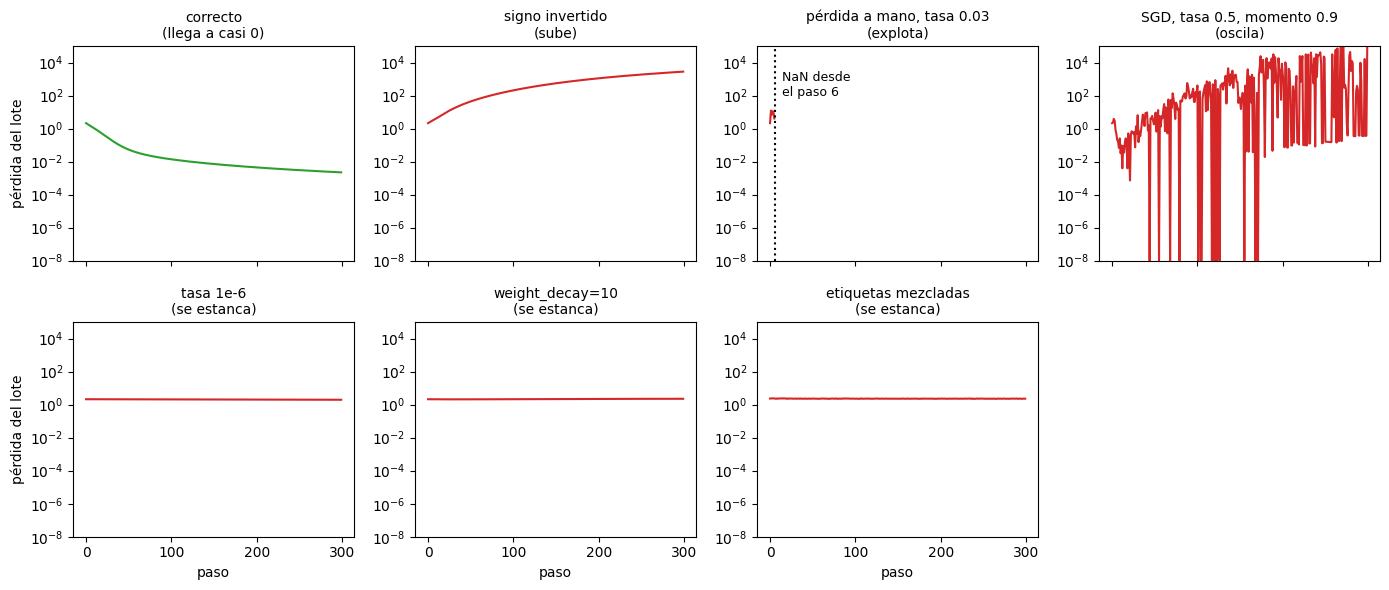

In [7]:
firmas = {
    "correcto": "llega a casi 0",
    "signo invertido": "sube",
    "pérdida a mano, tasa 0.03": "explota",
    "SGD, tasa 0.5, momento 0.9": "oscila",
    "tasa 1e-6": "se estanca",
    "weight_decay=10": "se estanca",
    "etiquetas mezcladas": "se estanca",
}
fig, ejes = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
for eje, (nombre, h) in zip(ejes.flat, historias.items()):
    valores = torch.tensor(h)
    finitos = torch.isfinite(valores)
    # una pérdida de exactamente 0 no cabe en escala logarítmica: se dibuja en 1e-8
    eje.plot(torch.arange(len(h))[finitos], valores[finitos].clamp(min=1e-8),
             color="tab:red" if nombre != "correcto" else "tab:green")
    if not finitos.all():
        primer = int((~finitos).nonzero()[0])
        eje.axvline(primer, color="black", linestyle=":")
        eje.text(primer + 8, 1e2, f"NaN desde\nel paso {primer}", fontsize=9)
    eje.set_yscale("log")
    eje.set_ylim(1e-8, 1e5)
    eje.set_title(f"{nombre}\n({firmas[nombre]})", fontsize=10)
ejes.flat[-1].axis("off")
for eje in ejes[1]:
    eje.set_xlabel("paso")
for eje in ejes[:, 0]:
    eje.set_ylabel("pérdida del lote")
plt.tight_layout()
plt.show()

Cada bug deja su firma:

- **Signo invertido**: la pérdida sube sin parar, hasta 2810 en el paso 299. Cada paso del optimizador es un paso cuesta arriba.
- **Pérdida a mano**: los primeros pasos son idénticos a los de un entrenamiento normal, y en el paso 6 aparece un `NaN` que ya no se va.
- **SGD con tasa 0.5 y momento 0.9**: la pérdida baja a 0.03 en 10 pasos, como si todo funcionara, y desde ahí salta una y otra vez entre casi 0 y decenas de miles. Con momento, cada paso arrastra a los anteriores, y con una tasa tan alta el paso acumulado se pasa del mínimo hacia el otro lado.
- **Tasa $10^{-6}$**: en 300 pasos la pérdida baja de 2.13 a 1.98. No hay nada roto, pero a ese ritmo memorizar 64 imágenes tomaría decenas de miles de pasos.
- **`weight_decay=10`**: la pérdida baja un poco y vuelve a subir, hasta 2.27. El decaimiento empuja los pesos hacia 0 con más fuerza que la que tiene la pérdida para sacarlos de ahí, así que la red queda cerca de no decir nada.
- **Etiquetas mezcladas**: la pérdida se queda alrededor de 2.3. Como cada imagen recibe una etiqueta distinta en cada paso, no hay nada que memorizar, y lo mejor que puede hacer la red es repartir la probabilidad según cuántas veces aparece cada dígito en el lote.

Ninguno de estos entrenamientos lanzó una excepción. Además, los tres últimos se parecen mucho: una curva que se estanca no dice cuál de las causas es. Por eso FSDL sugiere descartarlas en orden (la última fila de la tabla): subir la tasa, quitar la regularización y, si sigue igual, revisar la pérdida y los datos.

¿De dónde sale el `NaN`? Comparamos paso a paso la pérdida escrita a mano con `F.cross_entropy`, con la misma tasa:

In [8]:
estable = sobreajustar(optimizador=lambda p: torch.optim.Adam(p, lr=0.03))
inestable = historias["pérdida a mano, tasa 0.03"]
print("tasa 0.03     pérdida a mano   F.cross_entropy")
for paso in [0, 1, 2, 3, 4, 5, 6, 50, 299]:
    print(f"  paso {paso:3d}: {inestable[paso]:14.4g} {estable[paso]:17.4g}")
maximo = torch.finfo(torch.float32).max
print(f"mayor float32: {maximo:.3g} = e^{math.log(maximo):.2f};  "
      f"exp(88.0) = {torch.exp(torch.tensor(88.0)):.3g};  exp(89.0) = {torch.exp(torch.tensor(89.0))}")

tasa 0.03     pérdida a mano   F.cross_entropy
  paso   0:          2.133             2.133
  paso   1:           12.3              12.3
  paso   2:          6.845             6.845
  paso   3:          11.29             11.29
  paso   4:          10.18             10.18
  paso   5:          4.088             4.088
  paso   6:            nan             1.172
  paso  50:            nan         8.024e-05
  paso 299:            nan         7.724e-06
mayor float32: 3.4e+38 = e^88.72;  exp(88.0) = 1.65e+38;  exp(89.0) = inf


Las dos pérdidas dan el mismo número mientras los logits son moderados. Pero la tasa alta los hace crecer rápido, y en el paso 6 el mayor logit pasa de 88.7. El mayor número que cabe en un `float32` es $3.4 \times 10^{38} \approx e^{88.7}$, así que `exp` devuelve `inf`, la división da `inf / inf = NaN`, y el `NaN` se propaga por el gradiente a todos los pesos. `F.cross_entropy` calcula lo mismo con `logsumexp`, que resta el logit mayor antes de exponenciar, y con la misma tasa sobrevive a los saltos de los primeros pasos y termina en 0.000008. El bug no era la tasa alta: era la pérdida escrita a mano. La tasa alta solo lo hizo aparecer.

### Lo que esta prueba no ve

Un último bug, más traicionero: las etiquetas están desordenadas respecto de las imágenes, pero siempre de la misma forma. Pasa, por ejemplo, si se ordenan las imágenes por nombre de archivo y las etiquetas por otro criterio. Cada imagen tiene una etiqueta fija, solo que casi siempre es la de otra imagen.

In [9]:
desorden_fijo = torch.randperm(64, generator=torch.Generator().manual_seed(2))
desalineado = sobreajustar(etiquetas=lambda y, generador: y[desorden_fijo])
print(f"etiquetas que quedaron en su lugar: {(yb[desorden_fijo] == yb).sum().item()} de 64")
for paso in [0, 50, 100, 200, 299]:
    print(f"paso {paso:3d}: pérdida {desalineado[paso]:.5f}")

etiquetas que quedaron en su lugar: 2 de 64
paso   0: pérdida 2.51355
paso  50: pérdida 0.18342
paso 100: pérdida 0.03641
paso 200: pérdida 0.00997
paso 299: pérdida 0.00479


Solo 2 de las 64 imágenes conservan su etiqueta, y aun así la red memoriza el lote: la pérdida llega a 0.005, casi tan bajo como con las etiquetas correctas. Con 200.000 parámetros, una red memoriza 64 etiquetas cualesquiera. [Zhang y otros](https://arxiv.org/abs/1611.03530) (2017, sección 1) mostraron que redes más grandes memorizan incluso las 50.000 imágenes de CIFAR-10 con etiquetas al azar: "Deep neural networks easily fit random labels". Sobreajustar un lote prueba que el código **puede** aprender, no que aprenda lo correcto.

## 7. Comparar con un resultado conocido

El tercer paso de la depuración es reproducir un resultado que se sepa correcto. FSDL los ordena según cuánto sirven ([*Debug*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging/debug)): una implementación oficial evaluada en datos parecidos a los nuestros; si no hay, una implementación oficial evaluada en un conjunto de referencia; si no, una implementación no oficial; y después, los resultados de un artículo sin código, los del modelo en un conjunto de referencia y los de un modelo parecido en datos parecidos. Aparte menciona una fuente que se subestima: las líneas base simples, que muestran si el modelo aprende algo.

Para MNIST la referencia es la tabla de la [página de Yann LeCun](https://web.archive.org/web/20200111073916/http://yann.lecun.com/exdb/mnist/), que reúne los errores de prueba publicados durante dos décadas. Algunas filas que se parecen a nuestro modelo, entrenadas con las 60.000 imágenes y sin preprocesamiento:

| Modelo | Error de prueba |
|---|---|
| clasificador lineal | 12.0% |
| red de 2 capas, 300 neuronas ocultas, error cuadrático | 4.7% |
| red de 2 capas, 800 neuronas ocultas, entropía cruzada | 1.6% |

Entrenamos la red simple, de 256 neuronas ocultas, con las 50.000 imágenes de entrenamiento durante cinco épocas, y otra vez con el bug de las etiquetas desalineadas, ahora en todo el conjunto:

In [10]:
inicio = time.perf_counter()
completo = entrenar(red(256), X_entrenamiento, y_entrenamiento, epocas=5)
desorden = torch.randperm(len(y_entrenamiento), generator=torch.Generator().manual_seed(3))
con_bug = entrenar(red(256), X_entrenamiento, y_entrenamiento[desorden], epocas=5)
print(f"red simple, etiquetas correctas:     error de validación {error(completo, X_validacion, y_validacion):.2%}")
print(f"red simple, etiquetas desalineadas:  error de validación {error(con_bug, X_validacion, y_validacion):.2%}")
print(f"({time.perf_counter() - inicio:.0f} s)")

red simple, etiquetas correctas:     error de validación 2.84%
red simple, etiquetas desalineadas:  error de validación 85.20%
(18 s)


Con las etiquetas correctas, 2.84% en validación tras solo cinco épocas: entre el 4.7% de la red de 300 neuronas con error cuadrático y el 1.6% de la de 800 con entropía cruzada. Coincide con lo conocido. Con las etiquetas desalineadas, 85.2%: peor que cualquier fila de la tabla, incluido el clasificador lineal, y cerca de lo que da adivinar. Ninguna referencia se le parece, y eso basta para saber que hay un bug, aunque el entrenamiento haya corrido sin errores y el lote de prueba se haya memorizado sin problemas.

## 8. Evaluar: sesgo y varianza

Con el código depurado, volvemos al problema simplificado de 10.000 imágenes. FSDL descompone el error de prueba en cuatro partes ([*Evaluate*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging/evaluate); la versión de 2021 define cada término en [*Bias-Variance Decomposition*](https://fullstackdeeplearning.com/spring2021/lecture-7/#bias-variance-decomposition)):

$$\text{error de prueba} = \underbrace{\text{error irreducible}}_{\text{lo que ningún modelo puede bajar}} + \underbrace{\text{sesgo}}_{\text{entrenamiento} - \text{irreducible}} + \underbrace{\text{varianza}}_{\text{validación} - \text{entrenamiento}} + \underbrace{\text{sobreajuste a la validación}}_{\text{prueba} - \text{validación}}$$

- El **error irreducible** no se conoce. FSDL sugiere estimarlo con una referencia fuerte, como el desempeño humano. Para MNIST usamos el mejor resultado de la tabla de LeCun: 0.23%, de un comité de 35 redes convolucionales entrenadas con distorsiones elásticas (Ciresan y otros, CVPR 2012).
- El **sesgo** (*bias*; FSDL lo llama *avoidable bias*) es cuánto le falta al modelo para ajustar sus propios datos de entrenamiento. Un sesgo alto es **subajuste**.
- La **varianza** es cuánto peor le va con datos que no vio. Una varianza alta es **sobreajuste**.
- El **sobreajuste a la validación** aparece porque elegimos el modelo mirando la validación. Lo medimos en la sección 11, con la prueba.

Entrenamos la red de 256 neuronas 20 épocas con las 10.000 imágenes:

In [11]:
IRREDUCIBLE = 0.0023


def descomponer(modelo, X, y):
    entrenamiento = error(modelo, X, y)
    validacion = error(modelo, X_validacion, y_validacion)
    sesgo = max(entrenamiento - IRREDUCIBLE, 0.0)        # memorizar puede dejarlo bajo el irreducible
    return {"entrenamiento": entrenamiento, "validación": validacion,
            "sesgo": sesgo, "varianza": validacion - IRREDUCIBLE - sesgo}


def mostrar(nombre, d):
    print(f"{nombre:34s} entrenamiento {d['entrenamiento']:6.2%}   validación {d['validación']:6.2%}"
          f"   sesgo {d['sesgo']:6.2%}   varianza {d['varianza']:6.2%}")


simple = entrenar(red(256), X_chico, y_chico, epocas=20)
mostrar("256 neuronas, 10.000 imágenes", descomponer(simple, X_chico, y_chico))

256 neuronas, 10.000 imágenes      entrenamiento  0.03%   validación  4.40%   sesgo  0.00%   varianza  4.17%


Error de entrenamiento 0.03% (3 imágenes de 10.000) y de validación 4.40%. Como el modelo memorizó su entrenamiento, el error de entrenamiento quedó por debajo del irreducible estimado. Eso no significa que el modelo sea mejor que el mejor resultado conocido, sino que sobre datos ya vistos el error puede llegar a 0. En ese caso contamos el sesgo como 0, y la varianza es todo lo que hay entre el irreducible y la validación: 4.17 puntos.

El diagnóstico es claro: **sobreajuste**. Casi todo el error es varianza.

## 9. Mejorar: primero el sesgo, después la varianza

FSDL da una lista ordenada de remedios para cada caso, y pide atacar primero el subajuste y después el sobreajuste ([*Improve*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging/improve)). Para el **subajuste**: agregar complejidad al modelo, reducir la regularización, analizar los errores, elegir una arquitectura más compleja, ajustar hiperparámetros y agregar variables. Para el **sobreajuste**: agregar datos de entrenamiento, agregar normalización, aumentar los datos, aumentar la regularización, analizar los errores, elegir una arquitectura más compleja (así aparece también en esta lista), ajustar hiperparámetros, detener antes el entrenamiento, quitar variables y reducir el modelo.

La regla es atacar primero el subajuste. Mientras el modelo no ajuste ni siquiera los datos de entrenamiento, no tiene sentido preocuparse de los datos que no vio.

Para ver la receta completa partimos de más atrás, con un modelo demasiado simple: el clasificador lineal. Después aplicamos los remedios en el orden de FSDL, midiendo la descomposición en cada paso:

1. **el clasificador lineal**, sin capa oculta;
2. **agregar complejidad**: una capa oculta de 32 neuronas;
3. **más complejidad**: 256 neuronas, la red de la sección 8;
4. **agregar datos**: las 50.000 imágenes de entrenamiento, 8 épocas (con cinco veces más datos, 8 épocas son el doble de pasos que las 20 épocas con 10.000);
5. **aumentar los datos**: además, cada imagen se desplaza al azar hasta 2 píxeles en cada eje cada vez que se usa.

El paso 3 es la red que ya entrenamos en la sección 8.

In [12]:
inicio = time.perf_counter()
pasos_mejora = {
    "1. lineal": (red(), X_chico, y_chico, 20, False),
    "2. 32 neuronas": (red(32), X_chico, y_chico, 20, False),
    "3. 256 neuronas": None,
    "4. + 50.000 imágenes": (red(256), X_entrenamiento, y_entrenamiento, 8, False),
    "5. + desplazamientos": (red(256), X_entrenamiento, y_entrenamiento, 8, True),
}
descomposiciones, modelos = {}, {}
for nombre, receta in pasos_mejora.items():
    if receta is None:
        modelos[nombre], X, y = simple, X_chico, y_chico
    else:
        modelo, X, y, epocas, aumentar = receta
        modelos[nombre] = entrenar(modelo, X, y, epocas, aumentar=aumentar)
    descomposiciones[nombre] = descomponer(modelos[nombre], X, y)
    mostrar(nombre, descomposiciones[nombre])
print(f"({time.perf_counter() - inicio:.0f} s)")

1. lineal                          entrenamiento  6.82%   validación  8.79%   sesgo  6.59%   varianza  1.97%


2. 32 neuronas                     entrenamiento  3.57%   validación  6.74%   sesgo  3.34%   varianza  3.17%
3. 256 neuronas                    entrenamiento  0.03%   validación  4.40%   sesgo  0.00%   varianza  4.17%


4. + 50.000 imágenes               entrenamiento  0.72%   validación  2.52%   sesgo  0.49%   varianza  1.80%


5. + desplazamientos               entrenamiento  2.29%   validación  2.67%   sesgo  2.06%   varianza  0.38%
(41 s)


Paso a paso:

1. **El clasificador lineal** tiene 6.82% de error en sus propios datos de entrenamiento. Casi todo su error de validación es sesgo: un hiperplano por clase no alcanza para separar los dígitos. Es el caso de subajuste, y el remedio es agregar complejidad.
2. **Con 32 neuronas ocultas** el sesgo baja de 6.59 a 3.34 puntos, y la varianza sube de 1.97 a 3.17: el modelo empieza a ajustar detalles que no se repiten fuera del entrenamiento.
3. **Con 256 neuronas** el sesgo desaparece y todo el error es varianza, 4.17 puntos. Ahora toca la lista del sobreajuste.
4. **Con cinco veces más datos** la varianza baja de 4.17 a 1.80 puntos. Memorizar 50.000 imágenes es más difícil que memorizar 10.000, y la red tiene que aprender patrones que sirvan para todas.
5. **Con los desplazamientos** la varianza baja a 0.38 puntos, pero el sesgo sube de 0.49 a 2.06, y el error de validación empeora un poco, de 2.52% a 2.67%. Con imágenes que se mueven en cada época, el entrenamiento es más difícil, y 8 épocas ya no alcanzan para ajustarlo.

El paso 5 no fue un retroceso: cambió la forma del error. Ahora el sesgo es la parte más grande, así que la receta manda volver a la lista del subajuste. El primer remedio, un modelo más grande, es lento en una CPU (queda como ejercicio). Otro es ajustar los hiperparámetros, y el número de épocas es uno de ellos. Seguimos entrenando el modelo del paso 5 durante 8 épocas más:

In [13]:
import copy

inicio = time.perf_counter()
nombre = "6. + 8 épocas más"
modelos[nombre] = entrenar(copy.deepcopy(modelos["5. + desplazamientos"]), X_entrenamiento, y_entrenamiento,
                           epocas=8, aumentar=True, semilla=2)
descomposiciones[nombre] = descomponer(modelos[nombre], X_entrenamiento, y_entrenamiento)
for n in ["4. + 50.000 imágenes", "5. + desplazamientos", nombre]:
    mostrar(n, descomposiciones[n])
print(f"({time.perf_counter() - inicio:.0f} s)")

4. + 50.000 imágenes               entrenamiento  0.72%   validación  2.52%   sesgo  0.49%   varianza  1.80%
5. + desplazamientos               entrenamiento  2.29%   validación  2.67%   sesgo  2.06%   varianza  0.38%
6. + 8 épocas más                  entrenamiento  1.48%   validación  1.99%   sesgo  1.25%   varianza  0.51%
(19 s)


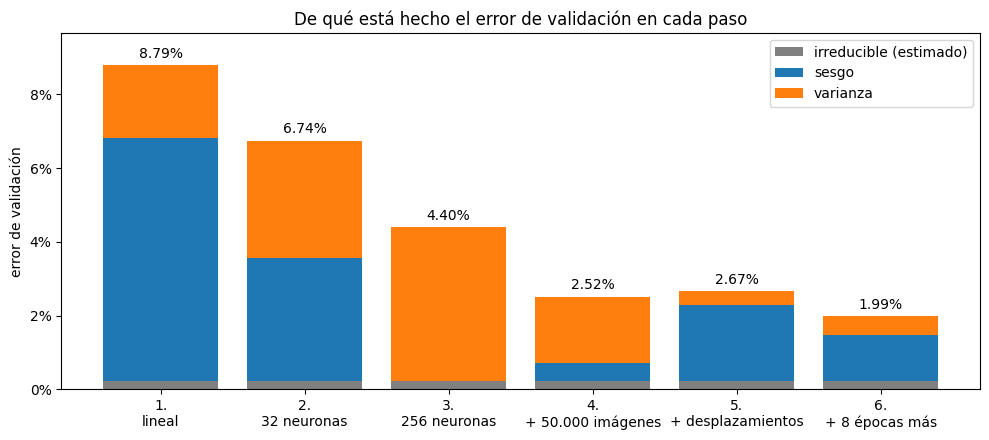

In [14]:
nombres = list(descomposiciones)
irreducible = [IRREDUCIBLE] * len(nombres)
sesgo = [descomposiciones[n]["sesgo"] for n in nombres]
varianza = [descomposiciones[n]["varianza"] for n in nombres]

etiquetas = [n.replace(". ", ".\n", 1) for n in nombres]
fig, eje = plt.subplots(figsize=(10, 4.5))
eje.bar(etiquetas, irreducible, color="gray", label="irreducible (estimado)")
eje.bar(etiquetas, sesgo, bottom=irreducible, color="tab:blue", label="sesgo")
eje.bar(etiquetas, varianza, bottom=[a + b for a, b in zip(irreducible, sesgo)], color="tab:orange", label="varianza")
for i, n in enumerate(nombres):
    eje.text(i, descomposiciones[n]["validación"] + 0.002, f"{descomposiciones[n]['validación']:.2%}", ha="center")
eje.set_ylabel("error de validación")
eje.set_ylim(0, 1.1 * max(d["validación"] for d in descomposiciones.values()))
eje.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
eje.set_title("De qué está hecho el error de validación en cada paso")
eje.legend()
plt.tight_layout()
plt.show()

Con 8 épocas más, el error de entrenamiento baja de 2.29% a 1.48%, la varianza casi no cambia y la validación llega a 1.99%, el mejor resultado hasta ahora. El gráfico resume el recorrido: el error pasó de 8.79% a 1.99%, y en cada paso la descomposición dijo qué atacar. Sin ella, frente al 4.40% del paso 3 habría sido tentador agrandar el modelo, que ya tenía sesgo 0.

## 10. Ajustar hiperparámetros

FSDL clasifica los hiperparámetros según cuánto afectan el resultado ([*Tune*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging/tune)):

- **poco**: el optimizador, el tamaño de lote, la activación;
- **algo**: la inicialización, la profundidad, otros parámetros de las capas, el peso de la regularización;
- **mucho**: la tasa de aprendizaje, su calendario, la función de pérdida, el tamaño de las capas.

Y compara varias formas de buscar. La **búsqueda en grilla** prueba todas las combinaciones de unos pocos valores. La **búsqueda aleatoria** sortea cada combinación, y según FSDL suele dar mejores resultados que la grilla. La de **lo grueso a lo fino** parte con una búsqueda aleatoria en un rango muy amplio, se queda con los mejores resultados y busca de nuevo cerca de sus valores ([2021, sección 7](https://fullstackdeeplearning.com/spring2021/lecture-7/#techniques-for-tuning-hyperparameter-optimization)). La lección menciona además la optimización bayesiana, la más eficiente sin intervención manual pero difícil de implementar desde cero, y recomienda empezar por lo grueso a lo fino.

¿Por qué la aleatoria suele ganarle a la grilla con el mismo presupuesto? Porque casi siempre hay un hiperparámetro que importa mucho más que los otros. Con una grilla de $3 \times 3$ se hacen nueve entrenamientos pero se prueban solo tres valores de la tasa de aprendizaje; con nueve sorteos se prueban nueve. Este argumento no está en las notas de FSDL: es de [Bergstra y Bengio](https://www.jmlr.org/papers/v13/bergstra12a.html) (2012), que lo resumen así: "only a few of the hyper-parameters really matter". Lo comprobamos con dos hiperparámetros: la tasa de aprendizaje, entre $10^{-5}$ y $10^{-1}$, y el ancho de la capa oculta, entre 16 y 1024, ambos en escala logarítmica. Cada prueba entrena 2 épocas con las 10.000 imágenes.

In [15]:
def probar(lr, ancho):
    modelo = entrenar(red(ancho), X_chico, y_chico, epocas=2, lr=lr)
    return error(modelo, X_validacion, y_validacion)


def sortear(n, lr_min, lr_max, ancho_min, ancho_max, semilla):
    generador = torch.Generator().manual_seed(semilla)
    u = torch.rand(n, 2, generator=generador)
    lrs = 10 ** (math.log10(lr_min) + u[:, 0] * (math.log10(lr_max) - math.log10(lr_min)))
    anchos = (2 ** (math.log2(ancho_min) + u[:, 1] * (math.log2(ancho_max) - math.log2(ancho_min)))).round()
    return [(lr.item(), int(a)) for lr, a in zip(lrs, anchos)]


inicio = time.perf_counter()
grilla = [(lr, ancho) for lr in [1e-5, 1e-3, 1e-1] for ancho in [16, 128, 1024]]
otra_grilla = [(lr, ancho) for lr in [3e-5, 3e-3, 3e-1] for ancho in [16, 128, 1024]]
aleatoria = sortear(9, 1e-5, 1e-1, 16, 1024, semilla=0)
resultados = {
    "grilla": [(lr, ancho, probar(lr, ancho)) for lr, ancho in grilla],
    "otra grilla": [(lr, ancho, probar(lr, ancho)) for lr, ancho in otra_grilla],
    "aleatoria": [(lr, ancho, probar(lr, ancho)) for lr, ancho in aleatoria],
}
for metodo, filas in resultados.items():
    lr, ancho, mejor = min(filas, key=lambda f: f[2])
    print(f"{metodo:12s} mejor: tasa {lr:.1e}, ancho {ancho:4d}  ->  error de validación {mejor:.2%}")
print(f"({time.perf_counter() - inicio:.0f} s)")

print()
print("primera grilla, error de validación:   ancho 16   ancho 128  ancho 1024")
for tasa in [1e-5, 1e-3, 1e-1]:
    fila = [e for lr, ancho, e in resultados["grilla"] if lr == tasa]
    print(f"  tasa {tasa:.0e}                    " + "".join(f"{e:11.2%}" for e in fila))

grilla       mejor: tasa 1.0e-03, ancho 1024  ->  error de validación 5.55%
otra grilla  mejor: tasa 3.0e-03, ancho 1024  ->  error de validación 6.37%
aleatoria    mejor: tasa 9.7e-04, ancho  391  ->  error de validación 5.70%
(24 s)

primera grilla, error de validación:   ancho 16   ancho 128  ancho 1024
  tasa 1e-05                         85.64%     57.42%     23.79%
  tasa 1e-03                         10.67%      7.00%      5.55%
  tasa 1e-01                         84.95%     65.77%     48.52%


La primera grilla obtuvo el mejor resultado de las tres búsquedas, 5.55%. Pero tuvo suerte: uno de sus tres valores de la tasa, $10^{-3}$, cayó justo en la zona buena. La segunda grilla, igual de razonable (cada valor es el anterior por 3), no tuvo esa suerte y quedó en 6.37%. La búsqueda aleatoria, con 9.7e-4, encontró sola la misma zona.

Además, las diferencias entre 5.55%, 5.70% y lo que sigue son chicas comparadas con el ruido de medir: con 10.000 imágenes de validación, un error de 5.6% tiene un margen de unos ±0.46 puntos (ver la sección 11). Lo que distingue a la búsqueda aleatoria se ve mejor en el gráfico. Hacemos también la segunda ronda, la fina, alrededor de la mejor prueba aleatoria: tasas entre un tercio y el triple de la mejor, y anchos entre la mitad y el doble.

zona fina: tasas entre 3.2e-04 y 2.9e-03, anchos entre 195 y 782
fina         mejor: tasa 1.4e-03, ancho  298  ->  error de validación 5.63%
las 9 pruebas finas: errores entre 5.63% y 7.20%


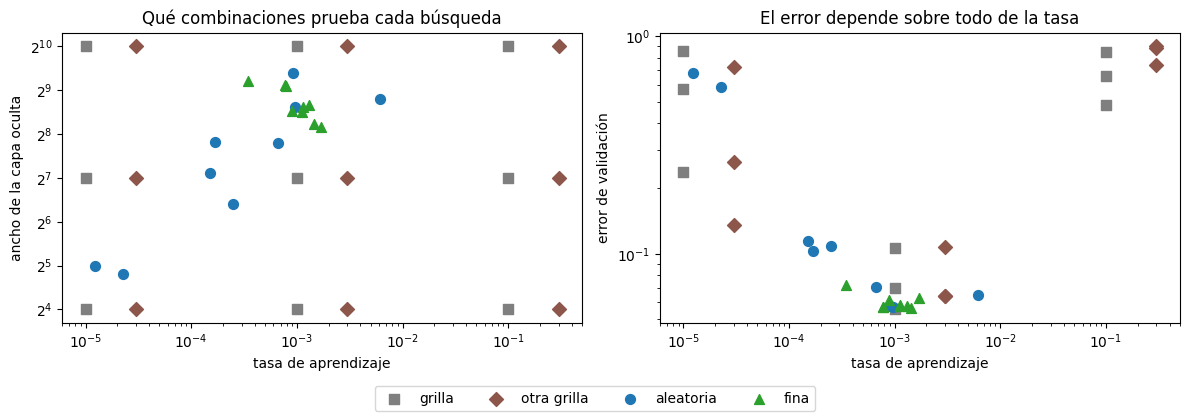

In [16]:
lr_mejor, ancho_mejor, _ = min(resultados["aleatoria"], key=lambda f: f[2])
fina = sortear(9, lr_mejor / 3, lr_mejor * 3, max(16, ancho_mejor // 2), min(2048, ancho_mejor * 2), semilla=1)
resultados["fina"] = [(lr, ancho, probar(lr, ancho)) for lr, ancho in fina]
lr, ancho, mejor = min(resultados["fina"], key=lambda f: f[2])
print(f"zona fina: tasas entre {lr_mejor / 3:.1e} y {lr_mejor * 3:.1e}, anchos entre {max(16, ancho_mejor // 2)} y {min(2048, ancho_mejor * 2)}")
print(f"fina         mejor: tasa {lr:.1e}, ancho {ancho:4d}  ->  error de validación {mejor:.2%}")
errores_finos = [f[2] for f in resultados["fina"]]
print(f"las 9 pruebas finas: errores entre {min(errores_finos):.2%} y {max(errores_finos):.2%}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
estilos = {"grilla": ("s", "tab:gray"), "otra grilla": ("D", "tab:brown"), "aleatoria": ("o", "tab:blue"),
           "fina": ("^", "tab:green")}
for metodo, filas in resultados.items():
    marcador, color = estilos[metodo]
    ejes[0].scatter([f[0] for f in filas], [f[1] for f in filas], marker=marcador, color=color, s=50, label=metodo)
    ejes[1].scatter([f[0] for f in filas], [f[2] for f in filas], marker=marcador, color=color, s=50)
ejes[0].set_yscale("log", base=2)
ejes[0].set_ylabel("ancho de la capa oculta")
ejes[0].set_title("Qué combinaciones prueba cada búsqueda")
ejes[1].set_yscale("log")
ejes[1].set_ylabel("error de validación")
ejes[1].set_title("El error depende sobre todo de la tasa")
for eje in ejes:
    eje.set_xscale("log")
    eje.set_xlabel("tasa de aprendizaje")
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

El gráfico de la izquierda muestra qué prueba cada búsqueda: las grillas solo tocan tres valores de la tasa y tres de ancho, mientras la aleatoria reparte sus nueve pruebas por todo el plano. El de la derecha muestra por qué eso importa: el error depende sobre todo de la tasa. Cada columna de puntos de las grillas tiene tres anchos muy distintos, 16, 128 y 1024. El ancho mueve el error, pero mucho menos que la tasa: con la tasa buena, $10^{-3}$, los tres anchos quedan entre 5.55% y 10.67%; con las tasas de los extremos, $10^{-5}$ y $10^{-1}$, ninguno baja de 23.79%. De las nueve pruebas de una grilla, entonces, solo tres exploran el hiperparámetro que más importa. La aleatoria dibuja la curva completa, con su valle alrededor de $10^{-3}$, y la búsqueda fina se concentra en ese valle: sus nueve pruebas quedan entre 5.63% y 7.20%, y la mejor llega a 5.63%.

Con 2 épocas por prueba, los errores son altos comparados con los de la sección 9. No importa: la búsqueda solo necesita ordenar las combinaciones de mejor a peor, y para eso alcanzan entrenamientos cortos.

## 11. La prueba, una sola vez

Queda el último término de la descomposición. El modelo final es el del paso 6 de la sección 9: lo elegimos mirando la validación, así que su error de validación puede ser optimista. La prueba, que no se usó para ninguna decisión, dice cuánto.

In [17]:
final = modelos["6. + 8 épocas más"]
d = descomposiciones["6. + 8 épocas más"]
prueba = error(final, X_prueba, y_prueba)
margen = 2 * math.sqrt(prueba * (1 - prueba) / len(y_prueba))
print(f"error irreducible (estimado): {IRREDUCIBLE:6.2%}")
print(f"sesgo:                        {d['sesgo']:6.2%}")
print(f"varianza:                     {d['varianza']:6.2%}")
print(f"sobreajuste a la validación:  {prueba - d['validación']:6.2%}")
print(f"error de prueba:              {prueba:6.2%}  (± {margen:.2%} con 95% de confianza)")

error irreducible (estimado):  0.23%
sesgo:                         1.25%
varianza:                      0.51%
sobreajuste a la validación:  -0.04%
error de prueba:               1.95%  (± 0.28% con 95% de confianza)


El error de prueba es 1.95%, y el término de sobreajuste a la validación sale ligeramente negativo: la prueba resultó un poco más fácil que la validación. No es una contradicción. Con 10.000 imágenes, un error de prueba de 1.95% tiene un margen de ±0.28 puntos con 95% de confianza (el intervalo de Wald: $\pm 2\sqrt{p(1-p)/n}$), así que una diferencia de 0.04 puntos es ruido. El modelo no sobreajustó la validación, en parte porque la usamos para pocas decisiones.

La descomposición final dice dónde seguir: el sesgo, 1.25 puntos, es más del doble que la varianza. Según la receta, el próximo paso sería un modelo con más capacidad; para imágenes, FSDL recomienda empezar por una red convolucional tipo LeNet ([2021, sección 3](https://fullstackdeeplearning.com/spring2021/lecture-7/#choose-a-simple-architecture)), que es el tema de un módulo posterior.

## 12. Resumen

- Depurar y ajustar se lleva la mayor parte del tiempo de un proyecto de deep learning. La receta de FSDL ordena ese trabajo: empezar simple, implementar y depurar, evaluar, mejorar y ajustar.
- **Empezar simple** es una red pequeña, Adam con tasa $3 \times 10^{-4}$, ReLU con inicialización de He, sin regularización, entradas normalizadas y unos 10.000 ejemplos.
- Antes de entrenar, una pasada hacia adelante ya permite revisar formas, rangos, `NaN` y la pérdida inicial, que para $K$ clases debería estar cerca de $\ln K$.
- **Sobreajustar un solo lote** es la prueba central: la pérdida tiene que llegar casi a 0. Si sube, hay un signo invertido; si explota, un problema numérico o una tasa muy alta; si oscila, una tasa alta o etiquetas mezcladas; si se estanca, una tasa baja, demasiada regularización o un error en los datos.
- La prueba no detecta etiquetas desalineadas de forma fija, porque una red memoriza cualquier etiqueta. Eso lo detecta la **comparación con un resultado conocido**.
- El error se descompone en irreducible, sesgo, varianza y sobreajuste a la validación. Se ataca primero el sesgo, con un modelo más grande, y después la varianza, con más datos y aumento de datos.
- En nuestra búsqueda, la tasa de aprendizaje fue el hiperparámetro que más importó, y FSDL la pone entre los de sensibilidad alta. Por eso la búsqueda aleatoria, que prueba un valor distinto de la tasa en cada intento, cubre mejor ese hiperparámetro que la grilla con el mismo presupuesto.

## Ejercicios

1. Siembra otro bug de la lista de FSDL: pásale a `nn.CrossEntropyLoss` las probabilidades de `softmax` en vez de los logits. ¿Qué firma deja al sobreajustar un lote? ¿Coincide con la tabla de la sección 6?
2. En `sobreajustar`, reemplaza el lote fijo por un lote nuevo en cada paso, tomado del conjunto de 10.000. ¿Sigue llegando la pérdida a 0? ¿Qué te dice eso sobre la diferencia entre memorizar y aprender?
3. Repite la sección 9 sin la inicialización de He (borra el ciclo que la aplica en `red`). ¿Cambia algún paso de la descomposición?
4. Agrega un paso 6 a la sección 9 con el siguiente remedio de la lista de sobreajuste de FSDL, la regularización: `weight_decay=1e-4` en Adam (o `AdamW`). ¿Baja la varianza? ¿Sube el sesgo?
5. Haz una búsqueda aleatoria de 9 pruebas sobre tres hiperparámetros: la tasa, el ancho y el tamaño de lote (entre 16 y 512). ¿Qué tan sensible es el resultado al tamaño de lote comparado con la tasa?

## Fuentes

Las citas textuales que respaldan cada afirmación, con el lugar exacto donde están. Las páginas se revisaron el 17 de octubre de 2026.

**Del material del curso**

- **Full Stack Deep Learning**, [*Training and Debugging*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging) (Josh Tobin, 2019). Cada subpágina tiene un video y un resumen:
  - [*Overview*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging/overview): "A common sentiment among practitioners is that they spend 80–90% of time debugging and tuning the models, and only 10–20% of time deriving math equations and implementing things."
  - [*Start Simple*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging/start-simple): "LeNet/ResNet for images. LSTM for sequences. Fully-connected network with one hidden layer for all other tasks", "ReLU activation for fully-connected and convolutional models and TanH activation for LSTM models", "Adam optimizer with a “magic” learning rate value of 3e-4", "He initialization for ReLU and Glorot initialization for TanH", "No regularization and data normalization", "Normalize data inputs: subtracting the mean and dividing by the variance" y "Working with a small training set around 10,000 examples" (sección 3).
  - [*Debug*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging/debug): los cinco bugs, de "Incorrect shapes for tensors" a "Numerical instability - inf/NaN" (sección 4); "Error goes up: Commonly this is due to a flip sign somewhere in the loss function/gradient", "Error explodes: This is usually a numerical issue, but can also be caused by a high learning rate", "Error oscillates: You can lower the learning rate and inspect the data for shuffled labels or incorrect data augmentation", "Error plateaus: You can increase the learning rate and get rid of regularization. Then you can inspect the loss function and the data pipeline for correctness" (secciones 5 y 6); y el orden de resultados conocidos, de "an official model implementation evaluated on a similar dataset to yours" a "simple baselines" (sección 7).
  - [*Evaluate*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging/evaluate): "Test error = irreducible error + bias + variance + validation overfitting" (sección 8).
  - [*Improve*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging/improve): "Add model complexity → Reduce regularization → Error analysis → Choose a more complex architecture → Tune hyper-parameters → Add features" y "Add more training data → Add normalization → Add data augmentation → Increase regularization → Error analysis → Choose a more complex architecture → Tune hyper-parameters → Early stopping → Remove features → Reduce model size" (sección 9).
  - [*Tune*](https://fall2019.fullstackdeeplearning.com/course-content/training-and-debugging/tune): "Low sensitivity: Optimizer, batch size, non-linearity", "Medium sensitivity: weight initialization, model depth, layer parameters, weight of regularization", "High sensitivity: learning rate, annealing schedule, loss function, layer size", y "Random search is also easy to implement and often produces better results than grid search" (sección 10).
- **Full Stack Deep Learning**, [*Lecture 7: Troubleshooting Deep Neural Networks*](https://fullstackdeeplearning.com/spring2021/lecture-7/) (2021, notas de James Le y Vishnu Rachakonda):
  - Secciones 1 y 2: "Most bugs in deep learning are actually invisible" y "Since it is hard to disambiguate errors, it’s best to start simple and gradually ramp up complexity".
  - Sección 3: "If your data looks like images, start with a LeNet-like architecture and consider using something like ResNet as your codebase gets more mature."
  - Sección 5: "Irreducible error is the baseline error you don’t expect your model to do better. It can be estimated through strong baselines, like human performance", "Avoidable bias, a measure of underfitting, is the difference between our train error and irreducible error", "Variance, a measure of overfitting, is the difference between validation error and training error", "Validation set overfitting is the difference between test error and validation error".
  - Sección 7: "Initially, start by defining a very large range to run a randomized search on. Within the pool of results, you can find N best results and hone in on the hyperparameter values used to generate those samples."
- **MNIST**, la página de Yann LeCun, Corinna Cortes y Christopher Burges. El link apunta a la [copia de enero de 2020 en el Internet Archive](https://web.archive.org/web/20200111073916/http://yann.lecun.com/exdb/mnist/), porque la dirección original no siempre responde. Filas de la tabla citadas en las secciones 7 y 8: "linear classifier (1-layer NN) none 12.0", "2-layer NN, 300 hidden units, mean square error none 4.7", "2-layer NN, 800 HU, Cross-Entropy Loss none 1.6 Simard et al., ICDAR 2003" y "committee of 35 conv. net, 1-20-P-40-P-150-10 [elastic distortions] width normalization 0.23 Ciresan et al. CVPR 2012".

**Artículos que no están en la lista del curso**

- C. Zhang, S. Bengio, M. Hardt, B. Recht y O. Vinyals (2017), [*Understanding deep learning requires rethinking generalization*](https://arxiv.org/abs/1611.03530), ICLR. Sección 1: "Deep neural networks easily fit random labels. More precisely, when trained on a completely random labeling of the true data, neural networks achieve 0 training error", con experimentos en CIFAR10 e ImageNet.
- J. Bergstra e Y. Bengio (2012), [*Random Search for Hyper-Parameter Optimization*](https://www.jmlr.org/papers/v13/bergstra12a.html), JMLR 13, 281–305. Resumen: "randomly chosen trials are more efficient for hyper-parameter optimization than trials on a grid" y "only a few of the hyper-parameters really matter".

**Lo que no viene de una fuente** son los números de este notebook (pérdidas, errores, la descomposición y las búsquedas): todos salen de las celdas de código. También son nuestros el zoológico de bugs y la prueba de las etiquetas desalineadas.